# 03 · Gruppen und Zusammenhänge: Zimmerart, Kapazität und Lage

## Teilfrage 3

> **Wie unterscheiden sich die Preisverteilungen nach Unterkunftsart, Kapazität und Arrondissement? Bleibt der Zusammenhang mit der Kapazität innerhalb der Unterkunftsarten bestehen, und wie stark überlappen die Gruppen?**

**Vorgehen und Begründung.** NB02 hat gezeigt, dass die Preise stark rechtsschief sind und einen schweren Tail haben. Daraus folgen die Werkzeuge:

- **Lage:** Mediane und Quartile je Gruppe, immer mit **n**.
- **Darstellung:** log-Achse. Die Werte bleiben in Euro.
- **Überlappung:** ECDF-Overlays und Quantilvergleiche. Ein Unterschied der Mediane sagt noch nicht, wie stark sich die Gruppen überschneiden.
- **Zusammenhang:** Rangmasse (Spearman ρ, Kendall τ) statt Pearson r, weil Pearson auf Extremwerte und Krümmung reagiert (VL04 S. 21–22).
- **Drittvariablen:** Zimmerart, Kapazität und Lage hängen miteinander zusammen. Wir vergleichen deshalb immer auch **innerhalb** von Gruppen (VL04 S. 36, 39–41).
- **Bedingte Anteile** mit absoluten Häufigkeiten (VL05 S. 16–18).

Eine Regression (VL10/11) setzen wir bewusst nicht ein. Wir arbeiten mit Schichtung, also Vergleichen innerhalb gleicher Gruppen. Das entspricht dem Stand der Vorlesung und bleibt nachvollziehbar.

**Vorlesungsbezug:** VL03 S. 15–25, 31; VL04 S. 8–10, 21–30, 36, 39–41, 44; VL05 S. 16–18. TA-Vorlagen: NB03 §1.1, §2.1–2.4, §3.1; NB04 §1.1, §3.1–3.3, §4.1, §4.3, §6.

**Aufbau**

1. Zimmerart: Lage, Streuung und Überlappung
2. Bedingte Anteile: Wer liegt im oberen Preisdezil?
3. Kapazität: Zusammenhang gesamt und innerhalb der Zimmerart
4. Drittvariable Kapazität: Wie viel vom Zimmerart-Unterschied bleibt bei gleicher Gästezahl?
5. Lage: Arrondissements in einem Vergleichssegment
6. Antwort auf Teilfrage 3

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Projektwurzel finden (Ordner mit src/), damit relative Pfade unabhängig vom Startordner gelten
PROJEKT = Path.cwd().resolve()
while not (PROJEKT / "src").is_dir():
    PROJEKT = PROJEKT.parent
sys.path.insert(0, str(PROJEKT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from scipy import stats

from src import daten as D
from src import grafik as G

G.stil()
SEED = D.SEED
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "'"))

print("Python    ", sys.version.split()[0])
for modul in (np, pd, scipy, matplotlib, sns):
    print(f"{modul.__name__:10s}", modul.__version__)
print("Seed      ", SEED)
print("Snapshot  ", D.SNAPSHOT)

alle, kern, _ = D.bereite_auf()
HAUPT = ["Entire home/apt", "Private room"]   # Hotel- und geteilte Zimmer: klein, nur beschrieben
print(f"\nKern: n = {G.zahl(len(kern))}")
print(kern["zimmerart"].value_counts().to_string())

Python     3.14.2
numpy      2.5.4
pandas     3.1.1
scipy      1.18.1
matplotlib 3.11.2
seaborn    0.13.2
Seed       42
Snapshot   2026-09-16



Kern: n = 37'584
zimmerart
Entire home/apt    32292
Private room        4908
Hotel room           266
Shared room          118


---
## 1. Zimmerart: Lage, Streuung und Überlappung

In [2]:
spalten = ["n", "Median", "Q1", "Q3", "IQR", "P90", "Mittelwert"]
nach_art = D.kennzahlen_je_gruppe(kern, "zimmerart")[spalten]
nach_art.insert(1, "Anteil am Kern (%)", (100 * nach_art["n"] / len(kern)).round(1))
assert nach_art["n"].sum() == len(kern)          # Nenner-Kontrolle: keine Zeile geht verloren
D.speichere_tabelle(nach_art, "03_kennzahlen_zimmerart")
nach_art.round(1)

,n,Anteil am Kern (%),Median,Q1,Q3,IQR,P90,Mittelwert
zimmerart,,,,,,,,
Entire home/apt,32'292.00,85.90,252.00,172.60,402.50,229.90,665.00,378.20
Private room,4'908.00,13.10,160.40,105.90,266.70,160.80,444.60,299.70
Hotel room,266.00,0.70,328.00,208.90,532.30,323.50,869.90,410.20
Shared room,118.00,0.30,58.00,46.20,80.10,33.90,172.20,95.20


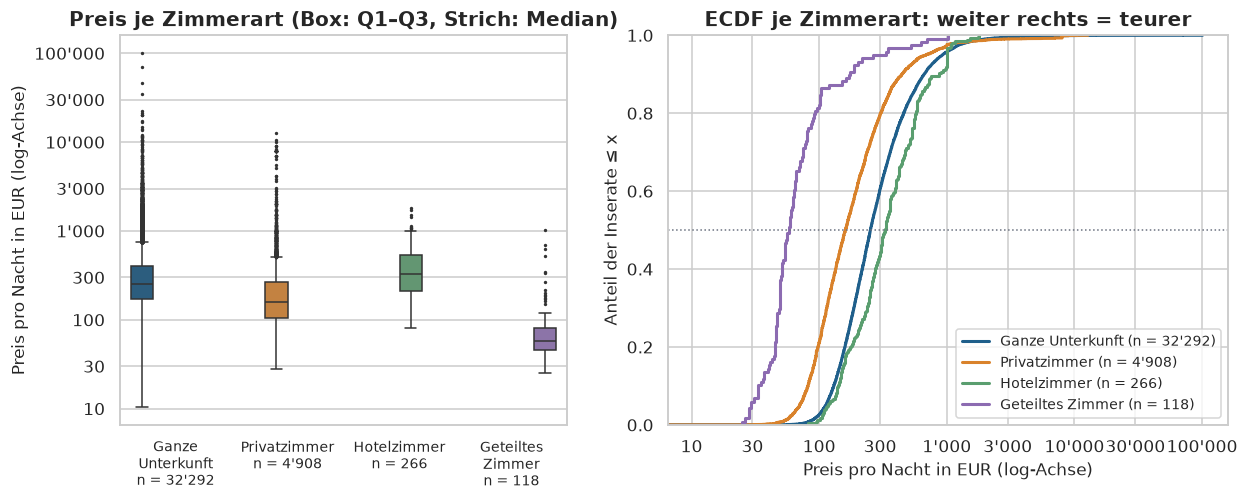

In [3]:
fig, achsen = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})

# Links: Boxplot je Zimmerart (Tukey-Whisker 1.5·IQR; Punkte ausserhalb klein gezeigt, nicht gelöscht)
reihenfolge = D.ZIMMERART_REIHENFOLGE
sns.boxplot(data=kern, x="zimmerart", y="preis_eur", order=reihenfolge, hue="zimmerart", hue_order=reihenfolge,
            palette=G.FARBEN_ZIMMERART, whis=1.5, fliersize=1.2, ax=achsen[0], legend=False)
G.log_preisachse(achsen[0], achse="y")
achsen[0].set_xticks(range(4), [f"{D.ZIMMERART_DEUTSCH[a].replace(' ', chr(10))}\nn = {G.zahl(nach_art.loc[a, 'n'])}" for a in reihenfolge], fontsize=9)
achsen[0].set(xlabel=None, title="Preis je Zimmerart (Box: Q1–Q3, Strich: Median)")

# Rechts: ECDF-Overlay zeigt die Überlappung über die ganze Verteilung
for art in reihenfolge:
    sns.ecdfplot(x=kern.loc[kern["room_type"] == art, "preis_eur"], ax=achsen[1], color=G.FARBEN_ZIMMERART[art],
                 linewidth=2, label=f"{D.ZIMMERART_DEUTSCH[art]} (n = {G.zahl(nach_art.loc[art, 'n'])})")
achsen[1].axhline(0.5, color=G.GRAU, linestyle=":", linewidth=1)
G.log_preisachse(achsen[1])
achsen[1].set(ylabel="Anteil der Inserate ≤ x", title="ECDF je Zimmerart: weiter rechts = teurer")
achsen[1].legend(loc="lower right", fontsize=9)
G.speichere(fig, "03_zimmerart_box_ecdf")
plt.show()

In [4]:
# Überlappung in Zahlen: Wie viele Privatzimmer sind teurer als die typische ganze Unterkunft – und umgekehrt?
ganz = kern.loc[kern["room_type"] == "Entire home/apt", "preis_eur"]
privat = kern.loc[kern["room_type"] == "Private room", "preis_eur"]
ueberlappung = pd.Series({
    "Median Ganze Unterkunft (EUR)": ganz.median(),
    "Median Privatzimmer (EUR)": privat.median(),
    "Verhältnis der Mediane": ganz.median() / privat.median(),
    "Anteil Privatzimmer über Median Ganze Unterkunft (%)": 100 * (privat > ganz.median()).mean(),
    "Anteil Ganze Unterkunft unter Median Privatzimmer (%)": 100 * (ganz < privat.median()).mean(),
})
D.speichere_tabelle(ueberlappung.to_frame("Wert"), "03_ueberlappung_zimmerart")
display(ueberlappung.round(2).to_frame("Wert"))

# Kreuzen sich die ECDFs? Prüfung auf einem feinen log-Gitter, mit und ohne gekennzeichnete Extremwerte
def kreuzung(daten):
    e = np.sort(daten.loc[daten["room_type"] == "Entire home/apt", "preis_eur"])
    p = np.sort(daten.loc[daten["room_type"] == "Private room", "preis_eur"])
    gitter = np.logspace(2, 5, 4000)          # ab 100 EUR, damit der leere untere Rand nicht zählt
    f_e = np.searchsorted(e, gitter, side="right") / len(e)
    f_p = np.searchsorted(p, gitter, side="right") / len(p)
    ueber = gitter[f_p < f_e]                 # Privatzimmer-ECDF unter der von ganzen Unterkünften = Privatzimmer teurer
    return (ueber.min(), np.searchsorted(e, ueber.min()) / len(e)) if len(ueber) else (None, None)

x, anteil = kreuzung(kern)
print(f"Kern: Privatzimmer werden ab {x:,.0f} EUR 'teurer' (≈ P{100 * anteil:.1f} beider Gruppen)".replace(",", "'"))
print("ohne flag_extrem:", "keine Kreuzung" if kreuzung(kern[~kern["flag_extrem"]])[0] is None else kreuzung(kern[~kern["flag_extrem"]]))

,Wert
Median Ganze Unterkunft (EUR),252.00
Median Privatzimmer (EUR),160.42
Verhältnis der Mediane,1.57
Anteil Privatzimmer über Median Ganze Unterkunft (%),27.36
Anteil Ganze Unterkunft unter Median Privatzimmer (%),20.56


Kern: Privatzimmer werden ab 1'594 EUR 'teurer' (≈ P98.5 beider Gruppen)
ohne flag_extrem: keine Kreuzung


**Lesehilfe ECDF.** Eine Kurve, die weiter **rechts** (bzw. unten) liegt, gehört zur teureren Gruppe (VL03 S. 31). Wo eine waagrechte Linie die Kurven schneidet, liest man dasselbe Quantil in beiden Gruppen ab. Die gestrichelte Linie bei 0.5 zeigt die Mediane.

**Beobachtung**

- Der Median der **ganzen Unterkünfte** (252 €, n = 32 292) liegt beim 1.57-Fachen des Medians der **Privatzimmer** (160 €, n = 4 908).
- Hotelzimmer haben den höchsten Median (328 €), allerdings bei nur n = 266. Geteilte Zimmer liegen mit 58 € (n = 118) klar am tiefsten.
- Die ECDF der ganzen Unterkünfte liegt bis etwa zum 98.5. Perzentil rechts der Privatzimmer. Erst im obersten 1.5 % (ab etwa 1 600 €) kreuzen sich die Kurven: P99 liegt bei Privatzimmern bei 2 781 €, bei ganzen Unterkünften bei 1 963 €. **Ohne die 117 gekennzeichneten Extremwerte verschwindet die Kreuzung.**
- Trotzdem **überlappen die Verteilungen stark**: 27 % der Privatzimmer sind teurer als die typische ganze Unterkunft, und 21 % der ganzen Unterkünfte sind billiger als das typische Privatzimmer.

**Interpretation**

- Der Unterschied der **Lage** ist deutlich und gilt über fast die ganze Verteilung. Die Kreuzung ganz oben geht auf die zweifelhaften Privatzimmer-Preise zurück (NB02: 57 gekennzeichnete Privatzimmer). Sie ist kein Hinweis auf ein echtes Luxussegment bei Privatzimmern.
- Das sagt aber wenig über das einzelne Inserat. Die Zimmerart allein trennt «teuer» und «günstig» schlecht.
- Ob der Unterschied an der Zimmerart selbst liegt oder daran, dass ganze Unterkünfte mehr Gäste aufnehmen, klärt Abschnitt 4.

---
## 2. Bedingte Anteile: Wer liegt im oberen Preisdezil?

Wir prüfen, ob eine empirische bedingte Wahrscheinlichkeit die Frage ergänzt: Wie häufig ist ein Inserat einer Zimmerart «teuer»?

- **«Teuer»** heisst im **oberen Preisdezil des Kerns**: Preis > P90 = 643 €. Die Grenze wurde im Projektvorschlag festgelegt und ist nicht nach dem Ergebnis gewählt.
- Es sind **empirische Anteile** dieses Snapshots, kein Wahrscheinlichkeitsmodell. Ein Binomial- oder Poissonmodell wäre hier nicht gerechtfertigt: Die Inserate sind keine unabhängigen, gleichartigen Versuche (Host-Cluster), und gezählt wird nichts pro Zeitintervall (VL05 S. 37).

In [5]:
grenze_oben = kern["preis_eur"].quantile(0.9)
oben = kern["preis_eur"] > grenze_oben
print(f"Grenze oberes Dezil (P90 des Kerns): {grenze_oben:.2f} EUR; Inserate darüber: {G.zahl(oben.sum())} von {G.zahl(len(kern))}")

bedingt = pd.DataFrame({
    "Inserate (Nenner)": kern.groupby("zimmerart", observed=True).size(),
    "davon im oberen Dezil": oben.groupby(kern["zimmerart"], observed=True).sum(),
})
bedingt["P(oberes Dezil | Zimmerart) in %"] = (100 * bedingt["davon im oberen Dezil"] / bedingt["Inserate (Nenner)"]).round(1)
bedingt["P(Zimmerart | oberes Dezil) in %"] = (100 * bedingt["davon im oberen Dezil"] / oben.sum()).round(1)
bedingt["Anteil am Kern P(Zimmerart) in %"] = (100 * bedingt["Inserate (Nenner)"] / len(kern)).round(1)
assert bedingt["davon im oberen Dezil"].sum() == oben.sum()
D.speichere_tabelle(bedingt, "03_bedingte_anteile_zimmerart")
bedingt

Grenze oberes Dezil (P90 des Kerns): 643.15 EUR; Inserate darüber: 3'759 von 37'584


,Inserate (Nenner),davon im oberen Dezil,P(oberes Dezil | Zimmerart) in %,P(Zimmerart | oberes Dezil) in %,Anteil am Kern P(Zimmerart) in %
zimmerart,,,,,
Entire home/apt,32292,3454,10.70,91.90,85.90
Private room,4908,265,5.40,7.00,13.10
Hotel room,266,38,14.30,1.00,0.70
Shared room,118,2,1.70,0.10,0.30


**Beobachtung (in natürlichen Häufigkeiten, VL05 S. 17)**

- Von 32 292 ganzen Unterkünften liegen 3 454 im oberen Dezil (10.7 %).
- Von 4 908 Privatzimmern sind es 265 (5.4 %), von 266 Hotelzimmern 38 (14.3 %).
- Die Umkehrung: Von allen 3 759 Inseraten im oberen Dezil sind **91.9 % ganze Unterkünfte**. Ganze Unterkünfte machen aber auch schon 85.9 % des Kerns aus.

**Interpretation**

- P(oberes Dezil | Privatzimmer) ist nur halb so gross wie bei ganzen Unterkünften. Unmöglich sind teure Privatzimmer aber nicht.
- Die beiden Richtungen der Bedingung beantworten verschiedene Fragen (VL05 S. 18):
  - «Die teuren Inserate sind fast alle ganze Unterkünfte» (91.9 %) folgt vor allem daraus, dass ganze Unterkünfte die grosse Mehrheit sind.
  - Wer wissen will, wie wahrscheinlich ein Inserat einer Zimmerart teuer ist, braucht P(oberes Dezil | Zimmerart) = 10.7 %.

---
## 3. Kapazität: Zusammenhang gesamt und innerhalb der Zimmerart

**Darstellung.** `accommodates` hat nur ganzzahlige Werte von 1 bis 16 und sehr viele Ties. Ein Streudiagramm wäre ein Strichcode aus 37 584 übereinanderliegenden Punkten. Wir zeigen deshalb einen **Boxplot je Kapazitätsstufe** (NB04 §6, Schritt 5), getrennt nach Zimmerart. Die Stufen ab 9 Gästen fassen wir **nur für die Grafik** zusammen, weil sie wenige Inserate haben. Die Masse rechnen wir mit den Originalwerten.

**Masswahl (VL04 S. 30, Prüfpfad S. 44):**

- **Spearman ρ** als Hauptmass: Es misst einen monotonen Zusammenhang und ist robust gegen den schweren Tail.
- **Kendall τ** als Gegenprobe: Es kommt besser mit den vielen Ties zurecht.
- **Pearson r** nur als Kontrast, um zu zeigen, wie stark Extremwerte es verfälschen.

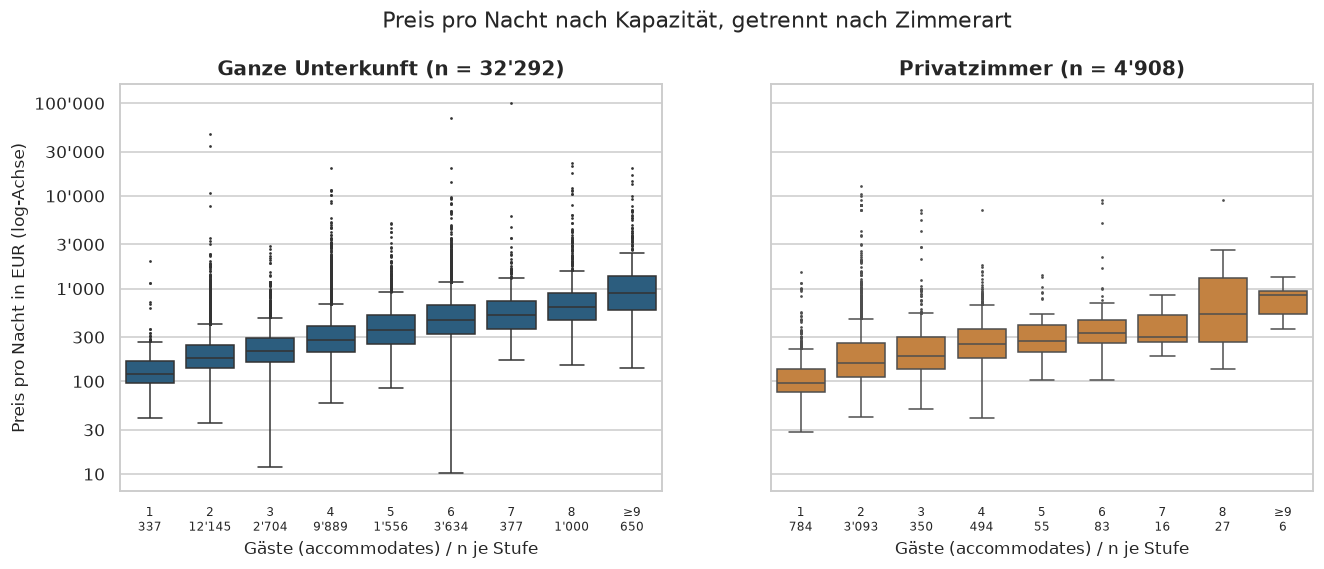

In [6]:
haupt = kern[kern["room_type"].isin(HAUPT)].copy()
haupt["kapazitaet_stufe"] = haupt["accommodates"].clip(upper=9).astype(int).astype(str).replace({"9": "≥9"})
stufen = [str(i) for i in range(1, 9)] + ["≥9"]

fig, achsen = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, art in zip(achsen, HAUPT):
    teil = haupt[haupt["room_type"] == art]
    sns.boxplot(data=teil, x="kapazitaet_stufe", y="preis_eur", order=stufen, color=G.FARBEN_ZIMMERART[art],
                whis=1.5, fliersize=0.8, ax=ax)
    n_stufe = teil["kapazitaet_stufe"].value_counts().reindex(stufen).fillna(0).astype(int)
    ax.set_xticks(range(len(stufen)), [f"{s}\n{G.zahl(n)}" for s, n in zip(stufen, n_stufe)], fontsize=8)
    ax.set(title=f"{D.ZIMMERART_DEUTSCH[art]} (n = {G.zahl(len(teil))})", xlabel="Gäste (accommodates) / n je Stufe")
G.log_preisachse(achsen[0], achse="y")
achsen[1].set_ylabel(None)
fig.suptitle("Preis pro Nacht nach Kapazität, getrennt nach Zimmerart", y=1.02)
G.speichere(fig, "03_kapazitaet_box")
plt.show()

In [7]:
median_je_stufe = haupt.pivot_table(index="accommodates", columns="room_type", values="preis_eur", aggfunc=["size", "median"])
median_je_stufe.columns = [f"{a} {b}" for a, b in median_je_stufe.columns]
pro_person = haupt[haupt["room_type"] == "Entire home/apt"].groupby("accommodates")["preis_pro_person"].median()
median_je_stufe["median Preis pro Person (Ganze Unterkunft)"] = pro_person
D.speichere_tabelle(median_je_stufe, "03_median_je_kapazitaet")
median_je_stufe.loc[1:10].round(1)

,size Entire home/apt,size Private room,median Entire home/apt,median Private room,median Preis pro Person (Ganze Unterkunft)
accommodates,,,,,
1,337.00,784.00,121.00,95.00,121.00
2,12'145.00,3'093.00,180.00,158.50,90.00
3,2'704.00,350.00,211.30,188.20,70.40
4,9'889.00,494.00,280.00,254.20,70.00
5,1'556.00,55.00,359.40,270.40,71.90
6,3'634.00,83.00,456.50,330.00,76.10
7,377.00,16.00,520.80,298.90,74.40
8,1'000.00,27.00,637.80,527.30,79.70
9,83.00,NaN,804.50,NaN,89.40


In [8]:
def zusammenhang(d: pd.DataFrame, x: str = "accommodates") -> pd.Series:
    return pd.Series({
        "n": len(d),
        "Spearman ρ": d[x].corr(d["preis_eur"], method="spearman"),
        "Kendall τ (b)": stats.kendalltau(d[x], d["preis_eur"]).statistic,
        "Pearson r": d[x].corr(d["preis_eur"]),
        "Pearson r ohne flag_extrem": d.loc[~d["flag_extrem"], x].corr(d.loc[~d["flag_extrem"], "preis_eur"]),
    })

gruppen_korr = {"alle Zimmerarten": kern} | {D.ZIMMERART_DEUTSCH[a]: kern[kern["room_type"] == a] for a in D.ZIMMERART_REIHENFOLGE}
korr = pd.DataFrame({name: zusammenhang(d) for name, d in gruppen_korr.items()}).T
korr["Spearman ρ mit bedrooms"] = [d["bedrooms"].corr(d["preis_eur"], method="spearman") for d in gruppen_korr.values()]

# Heikle Stelle selbst prüfen: Spearman = Pearson auf den Rängen (mittlere Ränge bei Ties, VL04 S. 27–28)
rho_hand = kern["accommodates"].rank().corr(kern["preis_eur"].rank())
assert np.isclose(rho_hand, korr.loc["alle Zimmerarten", "Spearman ρ"])
D.speichere_tabelle(korr, "03_korrelation_kapazitaet")
korr.round(3)

,n,Spearman ρ,Kendall τ (b),Pearson r,Pearson r ohne flag_extrem,Spearman ρ mit bedrooms
alle Zimmerarten,37'584.00,0.60,0.47,0.22,0.50,0.54
Ganze Unterkunft,32'292.00,0.60,0.47,0.23,0.50,0.57
Privatzimmer,4'908.00,0.43,0.34,0.11,0.33,0.19
Hotelzimmer,266.00,0.40,0.31,0.41,0.41,0.02
Geteiltes Zimmer,118.00,0.25,0.22,0.25,0.25,0.30


**Beobachtung**

- Bei ganzen Unterkünften steigt der Medianpreis mit jeder Kapazitätsstufe: von 121 € (1 Gast) über 180 € (2) und 280 € (4) bis 638 € (8). Die Boxen überlappen dabei zwischen benachbarten Stufen stark.
- Der **Preis pro Person** sinkt dagegen von 121 € (1 Gast) auf etwa 70 € (3–4 Gäste) und bleibt dann ungefähr gleich. Der Preis steigt also **weniger als proportional** zur Gästezahl.
- **Spearman ρ:**
  - über alle Zimmerarten 0.60 (n = 37 584)
  - innerhalb ganzer Unterkünfte 0.60
  - innerhalb der Privatzimmer 0.43
  - Kendall τ ist durchgehend kleiner (0.47 bzw. 0.34), wie es bei vielen Ties zu erwarten ist (VL04 S. 30). Die Rangfolge der Gruppen bleibt dieselbe.
- **Pearson r** liegt über alle Inserate nur bei 0.22. Ohne die 117 gekennzeichneten Extremwerte steigt r auf 0.50, während ρ unverändert bleibt.
- Mit `bedrooms` statt `accommodates` ergibt sich bei ganzen Unterkünften ein ähnliches Bild (ρ = 0.57).

**Interpretation**

- Zwischen Kapazität und Preis besteht ein **mittlerer bis starker monotoner Zusammenhang**. Er ist positiv, aber nicht linear: Pro zusätzlichem Gast steigt der Preis zunächst stärker, später schwächer.
- **Kein Simpson-Effekt:** Die Richtung ist innerhalb jeder Zimmerart positiv. Der Gesamtwert ist praktisch derselbe wie bei den ganzen Unterkünften, weil diese 86 % des Kerns ausmachen.
- Bei Privatzimmern ist der Zusammenhang schwächer. Plausibel ist, dass dort `accommodates` weniger über die Grösse des Raums aussagt (ein Zimmer für zwei statt einen Gast). Das ist eine **Vermutung**.
- Pearson r hätte den Zusammenhang wegen weniger Extremwerte als «schwach» ausgegeben. Die Wahl des Rangmasses ist hier also entscheidend.
- **Keine Kausalaussage:** Die Kapazität steht für vieles, was grössere Wohnungen sonst noch haben (Fläche, Ausstattung, Lage).

---
## 4. Drittvariable Kapazität: Wie viel vom Zimmerart-Unterschied bleibt bei gleicher Gästezahl?

Ganze Unterkünfte nehmen im Median 4 Gäste auf, Privatzimmer 2. Der Unterschied aus Abschnitt 1 könnte deshalb zum Teil ein **Kapazitätsunterschied** sein. Das ist das Muster «Drittvariable» aus VL04 S. 36 und NB04 §4.1. Wir vergleichen daher die Zimmerarten **bei gleicher Gästezahl**.

In [9]:
vergleich = haupt[haupt["accommodates"] <= 4].pivot_table(
    index="accommodates", columns="room_type", values="preis_eur", aggfunc=["size", "median"])
schicht = pd.DataFrame({
    "n Ganze Unterkunft": vergleich[("size", "Entire home/apt")],
    "n Privatzimmer": vergleich[("size", "Private room")],
    "Median Ganze Unterkunft": vergleich[("median", "Entire home/apt")],
    "Median Privatzimmer": vergleich[("median", "Private room")],
})
schicht["Verhältnis der Mediane"] = schicht["Median Ganze Unterkunft"] / schicht["Median Privatzimmer"]
gesamt_verhaeltnis = ganz.median() / privat.median()
print(f"Ohne Schichtung (alle Kapazitäten): Verhältnis der Mediane = {gesamt_verhaeltnis:.2f}")
print("Kapazität: Median Gäste", kern[kern["room_type"].isin(HAUPT)].groupby("room_type")["accommodates"].median().to_dict())
D.speichere_tabelle(schicht, "03_zimmerart_bei_gleicher_kapazitaet")
schicht.round(2)

Ohne Schichtung (alle Kapazitäten): Verhältnis der Mediane = 1.57
Kapazität: Median Gäste {'Entire home/apt': 4.0, 'Private room': 2.0}


,n Ganze Unterkunft,n Privatzimmer,Median Ganze Unterkunft,Median Privatzimmer,Verhältnis der Mediane
accommodates,,,,,
1,337,784,121.00,95.00,1.27
2,12145,3093,180.00,158.50,1.14
3,2704,350,211.28,188.25,1.12
4,9889,494,280.00,254.25,1.10


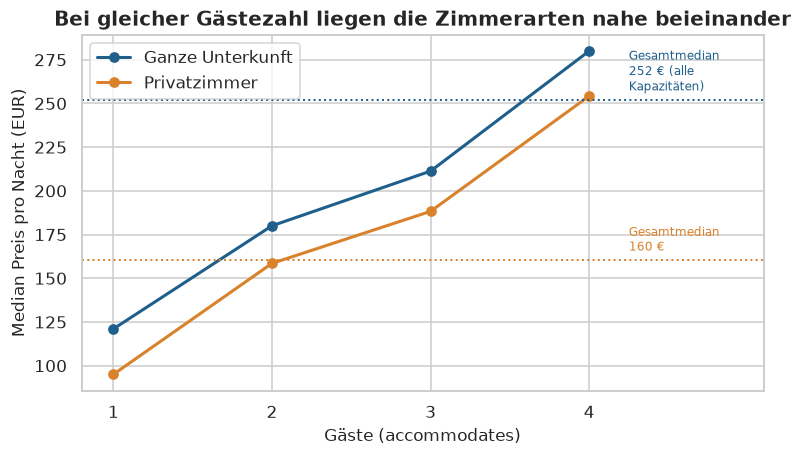

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for art in HAUPT:
    ax.plot(schicht.index, schicht[f"Median {D.ZIMMERART_DEUTSCH[art]}"], marker="o", linewidth=2,
            color=G.FARBEN_ZIMMERART[art], label=D.ZIMMERART_DEUTSCH[art])
for art, wert in [("Entire home/apt", ganz.median()), ("Private room", privat.median())]:
    ax.axhline(wert, color=G.FARBEN_ZIMMERART[art], linestyle=":", linewidth=1.3)
ax.text(4.25, ganz.median() + 3, f"Gesamtmedian\n{ganz.median():.0f} € (alle\nKapazitäten)", va="bottom", fontsize=8, color=G.FARBEN_ZIMMERART["Entire home/apt"])
ax.text(4.25, privat.median() + 3, f"Gesamtmedian\n{privat.median():.0f} €", va="bottom", fontsize=8, color=G.FARBEN_ZIMMERART["Private room"])
ax.set_xticks([1, 2, 3, 4])
ax.set(xlabel="Gäste (accommodates)", ylabel="Median Preis pro Nacht (EUR)", xlim=(0.8, 5.1),
       title="Bei gleicher Gästezahl liegen die Zimmerarten nahe beieinander")
ax.legend(loc="upper left")
G.speichere(fig, "03_zimmerart_gleiche_kapazitaet")
plt.show()

**Beobachtung**

- Ohne Schichtung kostet die typische ganze Unterkunft das **1.57-Fache** des typischen Privatzimmers.
- **Bei gleicher Gästezahl** schrumpft das Verhältnis auf **1.27** (1 Gast), **1.14** (2 Gäste), **1.12** (3) und **1.10** (4).
- Jede Zelle ist ausreichend besetzt: Die kleinste hat 337 Inserate (ganze Unterkunft für 1 Gast).

**Interpretation**

- Ein grosser Teil des rohen Zimmerart-Unterschieds geht auf die **Zusammensetzung** zurück: Ganze Unterkünfte nehmen typischerweise mehr Gäste auf. Bei gleicher Kapazität bleibt ein kleinerer, aber in allen vier Schichten gleichgerichteter Aufpreis für die ganze Unterkunft (+10 % bis +27 %).
- Die Rohzahl 1.57 ist deshalb **richtig als Beschreibung**, aber **irreführend als Vergleich gleichwertiger Angebote**.
- Auch der verbleibende Aufpreis ist keine Kausalwirkung. Andere Merkmale wie Lage, Ausstattung und Host-Typ sind nicht konstant gehalten.

---
## 5. Lage: Arrondissements in einem Vergleichssegment

Die Arrondissements unterscheiden sich auch in ihrer Zusammensetzung, zum Beispiel im Anteil ganzer Unterkünfte und in der Grösse der Inserate. Ein roher Vergleich der Mediane würde Lage und Zusammensetzung vermischen.

Wir vergleichen deshalb in einem festen **Vergleichssegment**: **ganze Unterkünfte für genau 2 Gäste**. Das ist das grösste homogene Segment (n = 12 145). Das Arrondissement ist nominal, deshalb rechnen wir **keine Korrelation**, sondern vergleichen Gruppen (NB04 §6, Schritt 5).

In [11]:
segment = kern[(kern["room_type"] == "Entire home/apt") & (kern["accommodates"] == 2)]
lage = segment.groupby("arrondissement")["preis_eur"].agg(
    n="size", Median="median", Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75)).sort_values("Median")
assert lage["n"].sum() == len(segment)
print(f"Segment: n = {G.zahl(len(segment))}; kleinstes Arrondissement im Segment: n = {lage['n'].min()}")
print(f"Median-Spanne: {lage['Median'].min():.0f} € ({lage.index[0]}) bis {lage['Median'].max():.0f} € ({lage.index[-1]}), "
      f"Faktor {lage['Median'].max() / lage['Median'].min():.2f}")
D.speichere_tabelle(lage, "03_lage_segment_2_gaeste")
lage.round(0)

Segment: n = 12'145; kleinstes Arrondissement im Segment: n = 302
Median-Spanne: 133 € (Ménilmontant) bis 271 € (Louvre), Faktor 2.04


,n,Median,Q1,Q3
arrondissement,,,,
Ménilmontant,720,133.00,107.00,167.00
Buttes-Chaumont,628,138.00,114.00,166.00
Gobelins,302,145.00,116.00,178.00
Reuilly,451,146.00,118.00,188.00
Buttes-Montmartre,1441,157.00,126.00,208.00
Observatoire,384,158.00,127.00,206.00
Popincourt,1156,171.00,135.00,226.00
Batignolles-Monceau,741,172.00,136.00,228.00
Entrepôt,856,175.00,139.00,226.00


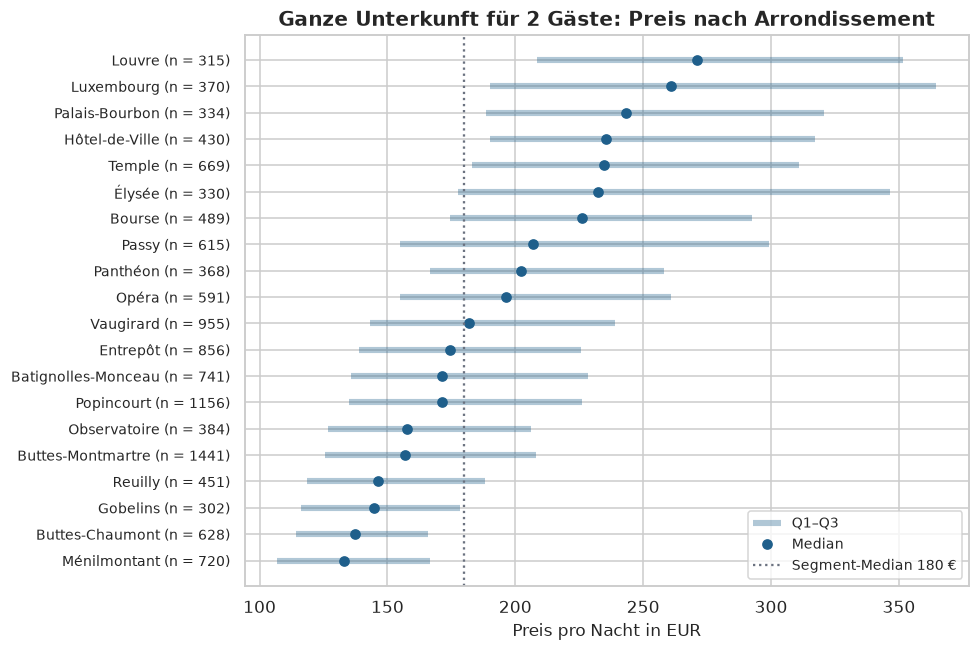

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
y = np.arange(len(lage))
ax.hlines(y, lage["Q1"], lage["Q3"], color=G.FARBEN_ZIMMERART["Entire home/apt"], linewidth=4, alpha=0.35, label="Q1–Q3")
ax.plot(lage["Median"], y, "o", color=G.FARBEN_ZIMMERART["Entire home/apt"], label="Median")
ax.axvline(segment["preis_eur"].median(), color=G.GRAU, linestyle=":", label=f"Segment-Median {segment['preis_eur'].median():.0f} €")
ax.set_yticks(y, [f"{a} (n = {n})" for a, n in zip(lage.index, lage["n"])], fontsize=9)
ax.set(xlabel="Preis pro Nacht in EUR", title="Ganze Unterkunft für 2 Gäste: Preis nach Arrondissement")
ax.legend(loc="lower right", fontsize=9)
G.speichere(fig, "03_lage_segment")
plt.show()

Ménilmontant: Anteil über dem Median von Louvre: 6.9% (n = 720)
Louvre: Anteil unter dem Median von Ménilmontant: 4.1% (n = 315)


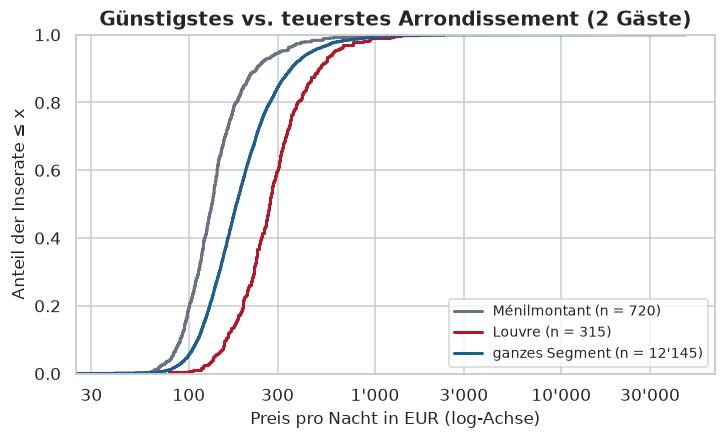

In [13]:
# Überlappung zwischen dem günstigsten und dem teuersten Arrondissement im Segment
guenstig, teuer = lage.index[0], lage.index[-1]
p_g = segment.loc[segment["arrondissement"] == guenstig, "preis_eur"]
p_t = segment.loc[segment["arrondissement"] == teuer, "preis_eur"]
print(f"{guenstig}: Anteil über dem Median von {teuer}: {(p_g > p_t.median()).mean():.1%} (n = {len(p_g)})")
print(f"{teuer}: Anteil unter dem Median von {guenstig}: {(p_t < p_g.median()).mean():.1%} (n = {len(p_t)})")

fig, ax = plt.subplots(figsize=(7.5, 4))
for name, werte, farbe in [(guenstig, p_g, G.GRAU), (teuer, p_t, G.AKZENT), ("ganzes Segment", segment["preis_eur"], G.FARBEN_ZIMMERART["Entire home/apt"])]:
    sns.ecdfplot(x=werte, ax=ax, color=farbe, linewidth=2, label=f"{name} (n = {G.zahl(len(werte))})")
G.log_preisachse(ax)
ax.set(ylabel="Anteil der Inserate ≤ x", title="Günstigstes vs. teuerstes Arrondissement (2 Gäste)")
ax.legend(loc="lower right", fontsize=9)
G.speichere(fig, "03_lage_ecdf_extreme")
plt.show()

In [14]:
# Ist die Rangfolge nur ein Zusammensetzungseffekt? Vergleich mit den Medianen über den ganzen Kern
median_kern = kern.groupby("arrondissement")["preis_eur"].median()
rho_rang = stats.spearmanr(median_kern[lage.index], lage["Median"]).statistic
zusammensetzung = kern.groupby("arrondissement").agg(
    **{"Anteil Ganze Unterkunft (%)": ("room_type", lambda s: 100 * (s == "Entire home/apt").mean()),
       "Median Gäste": ("accommodates", "median"),
       "Median Preis ganzer Kern": ("preis_eur", "median")}).loc[lage.index]
zusammensetzung["Median Preis Segment (2 Gäste)"] = lage["Median"]
print(f"Spearman ρ zwischen der Rangfolge im Segment und im ganzen Kern: {rho_rang:.3f}")
print(f"Spannweite Anteil ganzer Unterkünfte: {zusammensetzung['Anteil Ganze Unterkunft (%)'].min():.0f} % bis {zusammensetzung['Anteil Ganze Unterkunft (%)'].max():.0f} %")
zusammensetzung.round(1)

Spearman ρ zwischen der Rangfolge im Segment und im ganzen Kern: 0.965
Spannweite Anteil ganzer Unterkünfte: 78 % bis 93 %


,Anteil Ganze Unterkunft (%),Median Gäste,Median Preis ganzer Kern,Median Preis Segment (2 Gäste)
arrondissement,,,,
Ménilmontant,87.30,2.00,154.00,133.20
Buttes-Chaumont,85.40,3.00,162.00,137.50
Gobelins,80.00,3.00,179.10,144.90
Reuilly,82.00,3.00,184.50,146.20
Buttes-Montmartre,88.10,2.00,187.50,157.00
Observatoire,79.70,3.00,190.00,157.70
Popincourt,87.70,3.00,212.50,171.40
Batignolles-Monceau,84.40,3.00,221.60,171.50
Entrepôt,84.90,3.00,228.80,174.60


**Beobachtung**

- Im Segment «ganze Unterkunft, 2 Gäste» reichen die Arrondissement-Mediane von **133 € (Ménilmontant, n = 720)** bis **271 € (Louvre, n = 315)**. Das ist ein Faktor von 2.0.
- Günstig sind vor allem die nordöstlichen und östlichen Arrondissements (Ménilmontant, Buttes-Chaumont, Reuilly), teuer die zentralen (Louvre, Luxembourg, Palais-Bourbon, Hôtel-de-Ville, Temple) und Élysée.
- Zwischen den Extremen ist die Überlappung klein. Nur 6.9 % der Inserate in Ménilmontant sind teurer als der Median im Louvre, und 4.1 % im Louvre billiger als der Median in Ménilmontant.
- Benachbarte Ränge überlappen dagegen stark. Die Q1–Q3-Bänder der mittleren Arrondissements überschneiden sich fast vollständig.
- Die Rangfolge im Segment stimmt mit der Rangfolge über den ganzen Kern weitgehend überein (Spearman ρ = 0.97), obwohl der Anteil ganzer Unterkünfte zwischen 78 % und 93 % schwankt.

**Interpretation**

- Die Lage hängt **deutlich** mit dem Preis zusammen, auch bei festgehaltener Zimmerart und Kapazität. Der Unterschied zwischen den Extremen ist grösser als der Zimmerart-Unterschied bei gleicher Kapazität (Faktor 1.1–1.3).
- Die genaue Rangfolge in der Mitte ist **nicht scharf**, weil sich die Verteilungen dort stark überlappen.
- Auch hier gilt: Lage ist ein Bündel aus Nachfrage durch Touristen, Wohnungsqualität und Regulierung. Das Arrondissement **verursacht** den Preis nicht im engeren Sinn.

In [15]:
# Bedingte Anteile nach Lage. Grenze: P90 des Segments (Abweichung vom Kern-P90, siehe Text)
grenze_segment = segment["preis_eur"].quantile(0.9)
oben_seg = segment["preis_eur"] > grenze_segment
lage_bedingt = pd.DataFrame({
    "Inserate (Nenner)": segment.groupby("arrondissement").size(),
    "davon im oberen Segment-Dezil": oben_seg.groupby(segment["arrondissement"]).sum(),
})
lage_bedingt["P(oben | Arr.) %"] = (100 * lage_bedingt.iloc[:, 1] / lage_bedingt.iloc[:, 0]).round(1)
lage_bedingt["P(Arr. | oben) %"] = (100 * lage_bedingt.iloc[:, 1] / oben_seg.sum()).round(1)
lage_bedingt["P(Arr.) im Segment %"] = (100 * lage_bedingt.iloc[:, 0] / len(segment)).round(1)
print(f"Grenze: P90 des Segments = {grenze_segment:.0f} EUR; {oben_seg.sum()} von {G.zahl(len(segment))} Inseraten darüber")
print(f"Zum Vergleich mit der Kern-Grenze ({grenze_oben:.0f} EUR) lägen nur {(segment['preis_eur'] > grenze_oben).sum()} Segment-Inserate darüber.")
D.speichere_tabelle(lage_bedingt, "03_bedingte_anteile_lage")
lage_bedingt.sort_values("P(oben | Arr.) %")

Grenze: P90 des Segments = 355 EUR; 1206 von 12'145 Inseraten darüber
Zum Vergleich mit der Kern-Grenze (643 EUR) lägen nur 247 Segment-Inserate darüber.


,Inserate (Nenner),davon im oberen Segment-Dezil,P(oben | Arr.) %,P(Arr. | oben) %,P(Arr.) im Segment %
arrondissement,,,,,
Gobelins,302,6,2.00,0.50,2.50
Buttes-Chaumont,628,21,3.30,1.70,5.20
Reuilly,451,15,3.30,1.20,3.70
Ménilmontant,720,26,3.60,2.20,5.90
Observatoire,384,16,4.20,1.30,3.20
Entrepôt,856,44,5.10,3.60,7.00
Buttes-Montmartre,1441,74,5.10,6.10,11.90
Popincourt,1156,74,6.40,6.10,9.50
Batignolles-Monceau,741,63,8.50,5.20,6.10


**Abweichung vom Projektvorschlag (dokumentiert).** Der Vorschlag nannte das P90 des ganzen Kerns (643 €) als Grenze. Im Segment der Unterkünfte für 2 Gäste liegen darüber nur 247 Inserate, je Arrondissement also oft nur einstellige Zahlen. Innerhalb des Segments verwenden wir deshalb dessen eigenes P90 (355 €). Für die Zimmerarten in Abschnitt 2 gilt weiterhin die Kern-Grenze.

**Beobachtung**

- Im Luxembourg liegen 99 von 370 Inseraten (26.8 %) im oberen Dezil des Segments, in Gobelins 6 von 302 (2.0 %).
- **Vaugirard** zeigt, warum die Richtung der Bedingung wichtig ist: Vaugirard stellt 8.0 % der «teuren» Inserate, das klingt viel. Es macht aber auch 7.9 % des Segments aus, und nur 10.2 % seiner Inserate sind teuer. Das entspricht fast genau der Grundrate von 10 %.
- Luxembourg dagegen stellt 8.2 % der teuren Inserate bei nur 3.0 % Anteil am Segment.

**Interpretation.** P(Arr. | teuer) hängt stark von der **Grösse** des Arrondissements ab. Für die Frage «Wie wahrscheinlich ist ein Inserat in diesem Arrondissement teuer?» ist P(teuer | Arr.) die richtige Zahl (VL05 S. 18).

---
## 6. Antwort auf Teilfrage 3

**Zimmerart**

- Ganze Unterkünfte sind im Median deutlich teurer als Privatzimmer: 252 € gegenüber 160 €, also das 1.57-Fache. Das gilt bis etwa zum 98.5. Perzentil. Darüber kreuzen sich die ECDFs nur wegen gekennzeichneter Extremwerte.
- Die Verteilungen überlappen aber stark: Gut ein Viertel der Privatzimmer ist teurer als die typische ganze Unterkunft.
- **Bei gleicher Gästezahl** schrumpft der Unterschied auf das 1.10- bis 1.27-Fache. Ein grosser Teil des Rohunterschieds ist ein Kapazitätseffekt.

**Kapazität**

- Mittlerer bis starker monotoner Zusammenhang: ρ = 0.60 bei ganzen Unterkünften, 0.43 bei Privatzimmern.
- Er gilt innerhalb jeder Zimmerart, es gibt keinen Simpson-Effekt.
- Der Preis wächst weniger als proportional zur Gästezahl.
- Pearson r (0.22) unterschätzt den Zusammenhang wegen der Extremwerte deutlich.

**Lage**

- Bei festgehaltener Zimmerart und Kapazität (2 Gäste) reichen die Arrondissement-Mediane von 133 € bis 271 € (Faktor 2.0).
- Die Extreme überlappen kaum, die mittleren Arrondissements dagegen stark.
- Die Rangfolge ist auch über den ganzen Kern fast dieselbe (ρ = 0.97).

**Grenzen**

- Das sind Beschreibungen der angebotenen Abfragepreise eines Snapshots. Kausalaussagen machen wir keine.
- Die Schichtung hält jeweils nur eine Drittvariable fest.
- Termin der Abfrage und Mehrfach-Hosts sind noch nicht geprüft.

**Übergang zu NB04.** Wir prüfen, ob diese Aussagen bestehen bleiben, wenn wir Extremwerte, Abfragebedingungen und Mehrfach-Hosts anders behandeln. Gesucht sind Rechnungen, die die Aussagen **hätten widerlegen können**.